<a href="https://colab.research.google.com/github/archiedejarnette/DSA-405-Student/blob/main/DSA405_002_FA26_P4_hadejarn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# P4

## Analysis and Results

In [11]:
import pandas as pd
import numpy as np

#Load the final cleaned dataset by cloning the github repo

!git clone https://github.com/archiedejarnette/DSA-405-Student.git
%cd DSA-405-Student

movie_data = pd.read_csv("data/clean/movie_data.csv")

movie_data["release_date"] = pd.to_datetime(movie_data["release_date"])
movie_data.info()

Cloning into 'DSA-405-Student'...
remote: Enumerating objects: 172, done.
remote: Counting objects: 100% (70/70), done.
remote: Compressing objects: 100% (57/57), done.
remote: Total 172 (delta 33), reused 10 (delta 10), pack-reused 102 (from 1)
Receiving objects: 100% (172/172), 9.45 MiB | 15.53 MiB/s, done.
Resolving deltas: 100% (76/76), done.
/content/DSA-405-Student/DSA-405-Student/DSA-405-Student/DSA-405-Student
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5810 entries, 0 to 5809
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   id                      5810 non-null   int64         
 1   imdb_id                 5784 non-null   object        
 2   title                   5808 non-null   object        
 3   release_date            5810 non-null   datetime64[ns]
 4   genres                  5803 non-null   object        
 5   budget                  5810 non-null   int64 

In [12]:
#Testing the correlation between roi, budget, average popularity score of top 3 actors, number of votes on imdb, and average rating on imdb
print(movie_data[
    ["roi", "budget", "top_3_actor_popularity", "numVotes", "averageRating"]
].corr())

                             roi    budget  top_3_actor_popularity  numVotes  \
roi                     1.000000 -0.017188               -0.019121  0.003839   
budget                 -0.017188  1.000000                0.390269  0.481247   
top_3_actor_popularity -0.019121  0.390269                1.000000  0.336145   
numVotes                0.003839  0.481247                0.336145  1.000000   
averageRating           0.004678  0.085980                0.075812  0.421548   

                        averageRating  
roi                          0.004678  
budget                       0.085980  
top_3_actor_popularity       0.075812  
numVotes                     0.421548  
averageRating                1.000000  


**Modeling**

In [13]:
import statsmodels.api as sm

#Predictor variables
X = movie_data[
    ["top_3_actor_popularity", "budget"]
]

#Outcome variable
y = movie_data["roi"]

#Add the intercept term
X = sm.add_constant(X)

#Fit the regression model
model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    roi   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.386
Date:                Fri, 20 Nov 2026   Prob (F-statistic):              0.250
Time:                        09:45:41   Log-Likelihood:                -40710.
No. Observations:                5810   AIC:                         8.143e+04
Df Residuals:                    5807   BIC:                         8.145e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     17

The skew is 53.95, which is likely caused by movies that have a very low budget, which drastically increases their roi. I will perform the regression again, transforming the roi using a logarithm to reduce skew.

In [14]:
#Transform ROI so extreme values have less influence and transform budget so it is in millions
movie_data["budget_millions"] = movie_data["budget"] / 1_000_000
movie_data["log_roi_plus_1"] = np.log1p(movie_data["roi"])


X = movie_data[
    ["top_3_actor_popularity", "budget_millions"]
]

y = movie_data["log_roi_plus_1"]

X = sm.add_constant(X)

log_model_scaled = sm.OLS(y, X).fit()

print(log_model_scaled.summary())

                            OLS Regression Results                            
Dep. Variable:         log_roi_plus_1   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                  0.016
Method:                 Least Squares   F-statistic:                     48.48
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           1.32e-21
Time:                        09:45:41   Log-Likelihood:                -11672.
No. Observations:                5810   AIC:                         2.335e+04
Df Residuals:                    5807   BIC:                         2.337e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     -0

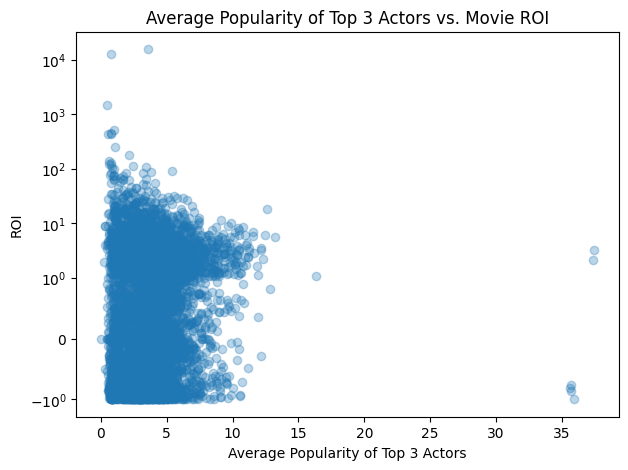

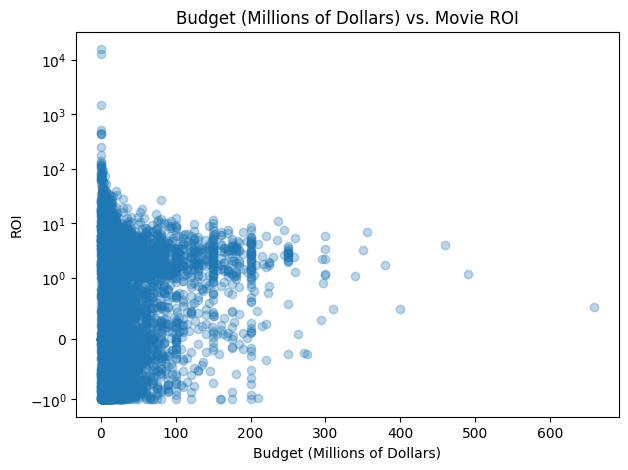

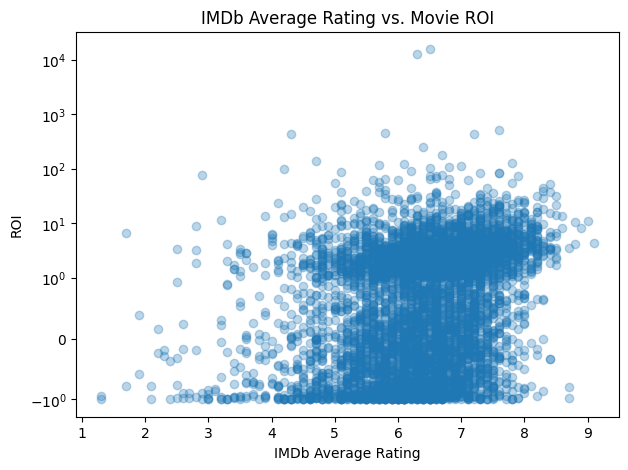

In [15]:
import matplotlib.pyplot as plt

variables = [
    ("top_3_actor_popularity", "Average Popularity of Top 3 Actors"),
    ("budget_millions", "Budget (Millions of Dollars)"),
    ("averageRating", "IMDb Average Rating")
]

for column, label in variables:
    plt.figure(figsize=(7, 5))

    plt.scatter(
        movie_data[column],
        movie_data["roi"],
        alpha=0.3
    )

    plt.yscale("symlog", linthresh=1)

    plt.xlabel(label)
    plt.ylabel("ROI")
    plt.title(f"{label} vs. Movie ROI")

    plt.show()

**Results**

The results from my analysis  suggested that there is no measurable relationship between actor popularity and roi, even when the production budget is accounted for. In the final OLS regression model, I logarithmically transformed the roi variable to reduce the skew of movies that had a very low production budget and a very high roi. The relationship between average popularity of the top 3 actors was not statistically significant with a p-value of 0.9. with the raw roi values, the correlation between top 3 actor popularity and roi was -.02, which doesn't show a strong correlation at all. The relationship between production budget and roi was statistically significant with a p-value less than 0.0001. However, the OLS model only explained 1.6% of the variation in ROI. There also was not a strong relationship between ROI and either the number of IMDb votes or the average IMDb rating, with raw correlation coefficients of 0.004 and 0.005, respectively. Ultimately, my analysis showed that there are many other factors that influence a movie's roi. No factor alone shows a strong positive or negative correlation with roi.